# Experiments: MLP Baseline, 1D-CNN, UMAP & Temporal Cross-Validation

This notebook evaluates three deep learning pipelines on the **Gas Sensor Array Drift Dataset**:
1. **MLP Baseline** (`GasMLP` on 128 standardized features)
2. **1D-CNN** (`Gas1DCNN` reshaping the 128 features into `8 channels x 16 sensors`)
3. **UMAP + MLP** (16-D UMAP embeddings fitted strictly on training folds + `GasMLP`)

We compare two validation protocols:
- **Protocol A (Random Stratified 5-Fold CV):** Standard non-temporal split (optimistic upper bound due to temporal drift leakage).
- **Protocol B (Chronological Expanding-Window CV):** Train on Batches `1..t`, test on Batch `t+1` for `t = 1..9` (realistic evaluation under sensor drift).

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler
import umap

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "src").exists() else cwd.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import GAS_LABELS, NUM_FEATURES, load_dataset
from src.models import Gas1DCNN, GasMLP
from src.train_eval import run_random_cv, run_temporal_cv, set_seed

FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

print(f"Project root: {PROJECT_ROOT}")
print(f"Using device: {DEVICE}")

Project root: C:\Users\z64x\Desktop\Deeplearn project
Using device: cuda


In [2]:
df = load_dataset(
    raw_dir=PROJECT_ROOT / "data" / "raw",
    processed_path=PROJECT_ROOT / "data" / "processed" / "gas_sensor_drift.parquet",
)
feature_cols = [f"f{i}" for i in range(1, NUM_FEATURES + 1)]
X = df[feature_cols].to_numpy(dtype=np.float32)
y = df["gas_id"].to_numpy(dtype=np.int64) - 1  # 0-indexed (0..5)
gas_names = [GAS_LABELS[i] for i in sorted(GAS_LABELS)]

TRAIN_CFG = {
    "epochs": 60,
    "batch_size": 128,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "patience": 12,
    "seed": 42,
}
UMAP_CFG = {
    "n_components": 16,
    "n_neighbors": 15,
    "min_dist": 0.1,
    "random_state": 42,
}

hyperparams = {
    "device": str(DEVICE),
    "mlp_hidden_dims": [256, 128, 64],
    "mlp_dropout": 0.3,
    "cnn_channels": [8, 32, 64, 128],
    "cnn_dropout": 0.3,
    "training": TRAIN_CFG,
    "umap_embedding": UMAP_CFG,
}
with open(RESULTS_DIR / "hyperparameters.json", "w", encoding="utf-8") as f:
    json.dump(hyperparams, f, indent=2)

print(f"Loaded X: {X.shape}, y: {y.shape}, classes: {gas_names}")

Loaded X: (13910, 128), y: (13910,), classes: ['Ethanol', 'Ethylene', 'Ammonia', 'Acetaldehyde', 'Acetone', 'Toluene']


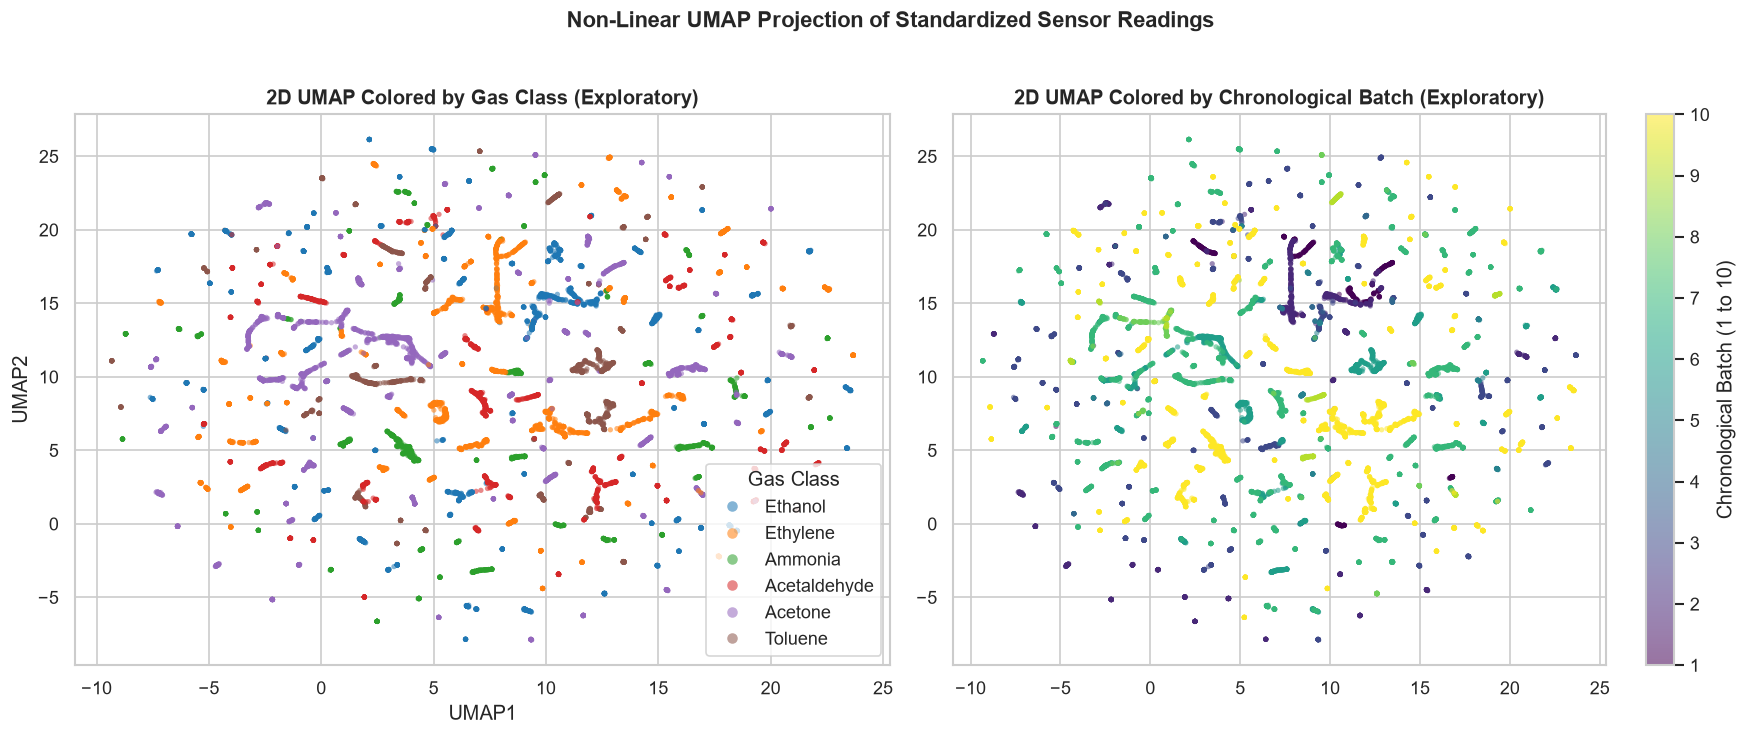

Saved figure: C:\Users\z64x\Desktop\Deeplearn project\figures\04_umap_2d_visualization.png


In [3]:
# 2D UMAP on standardized features (fitted on full dataset ONLY for exploratory visualization)
set_seed(42)
X_scaled_viz = StandardScaler().fit_transform(X)
umap_2d = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
X_umap_2d = umap_2d.fit_transform(X_scaled_viz)

viz_df = pd.DataFrame({
    "UMAP1": X_umap_2d[:, 0],
    "UMAP2": X_umap_2d[:, 1],
    "gas_name": df["gas_name"],
    "batch": df["batch"],
})

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=viz_df,
    x="UMAP1",
    y="UMAP2",
    hue="gas_name",
    hue_order=gas_names,
    palette="tab10",
    s=10,
    alpha=0.55,
    linewidth=0,
    ax=axes[0],
)
axes[0].set_title("2D UMAP Colored by Gas Class (Exploratory)", fontsize=12, fontweight="bold")
axes[0].legend(title="Gas Class", markerscale=2, frameon=True)

sc = axes[1].scatter(
    viz_df["UMAP1"],
    viz_df["UMAP2"],
    c=viz_df["batch"],
    cmap="viridis",
    s=10,
    alpha=0.55,
    edgecolors="none",
)
cbar = fig.colorbar(sc, ax=axes[1], ticks=range(1, 11))
cbar.set_label("Chronological Batch (1 to 10)")
axes[1].set_title("2D UMAP Colored by Chronological Batch (Exploratory)", fontsize=12, fontweight="bold")

fig.suptitle("Non-Linear UMAP Projection of Standardized Sensor Readings", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig4_path = FIGURES_DIR / "04_umap_2d_visualization.png"
fig.savefig(fig4_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig4_path}")

In [4]:
print("Running Protocol A: Random Stratified 5-Fold CV ...")
model_builders = {
    "MLP": lambda: GasMLP(input_dim=NUM_FEATURES, num_classes=6),
    "1D-CNN": lambda: Gas1DCNN(num_sensors=16, features_per_sensor=8, num_classes=6),
}
random_cv_summary = run_random_cv(
    X,
    y,
    model_builders=model_builders,
    n_splits=5,
    device=DEVICE,
    **TRAIN_CFG,
)
random_cv_summary.to_csv(RESULTS_DIR / "random_cv_summary.csv", index=False)
display(random_cv_summary)

Running Protocol A: Random Stratified 5-Fold CV ...


,model,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std
0,MLP,0.993098,0.003298,0.992801,0.003328,0.993094,0.003302
1,1D-CNN,0.993530,0.002142,0.993224,0.002505,0.993524,0.002145


In [5]:
print("Running Protocol B: Chronological Expanding-Window CV (Batches 1..t -> t+1) ...")
temporal_per_batch, pooled_preds, temporal_summary = run_temporal_cv(
    df,
    feature_cols=feature_cols,
    device=DEVICE,
    umap_dim=UMAP_CFG["n_components"],
    **TRAIN_CFG,
)
temporal_per_batch.to_csv(RESULTS_DIR / "temporal_cv_per_batch.csv", index=False)
temporal_summary.to_csv(RESULTS_DIR / "temporal_cv_summary.csv", index=False)

print("\nTemporal CV Summary:")
display(temporal_summary)

Running Protocol B: Chronological Expanding-Window CV (Batches 1..t -> t+1) ...


[Batch 1-1 -> 2] MLP acc=0.811 | 1D-CNN acc=0.758 | UMAP+MLP acc=0.593


[Batch 1-2 -> 3] MLP acc=0.793 | 1D-CNN acc=0.939 | UMAP+MLP acc=0.874


[Batch 1-3 -> 4] MLP acc=0.745 | 1D-CNN acc=0.752 | UMAP+MLP acc=0.770


[Batch 1-4 -> 5] MLP acc=0.995 | 1D-CNN acc=0.964 | UMAP+MLP acc=0.797


[Batch 1-5 -> 6] MLP acc=0.767 | 1D-CNN acc=0.721 | UMAP+MLP acc=0.667


[Batch 1-6 -> 7] MLP acc=0.844 | 1D-CNN acc=0.834 | UMAP+MLP acc=0.737


[Batch 1-7 -> 8] MLP acc=0.935 | 1D-CNN acc=0.915 | UMAP+MLP acc=0.745


[Batch 1-8 -> 9] MLP acc=0.768 | 1D-CNN acc=0.811 | UMAP+MLP acc=0.766


[Batch 1-9 -> 10] MLP acc=0.772 | 1D-CNN acc=0.679 | UMAP+MLP acc=0.517

Temporal CV Summary:


,model,mean_batch_accuracy,std_batch_accuracy,mean_batch_macro_f1,std_batch_macro_f1,pooled_accuracy,pooled_macro_f1,pooled_weighted_f1
0,MLP,0.825720,0.085437,0.786589,0.125056,0.803119,0.784545,0.803186
1,1D-CNN,0.819212,0.101481,0.777246,0.149407,0.780542,0.757023,0.777825
2,UMAP+MLP,0.718346,0.109193,0.698965,0.122190,0.671296,0.659637,0.678666


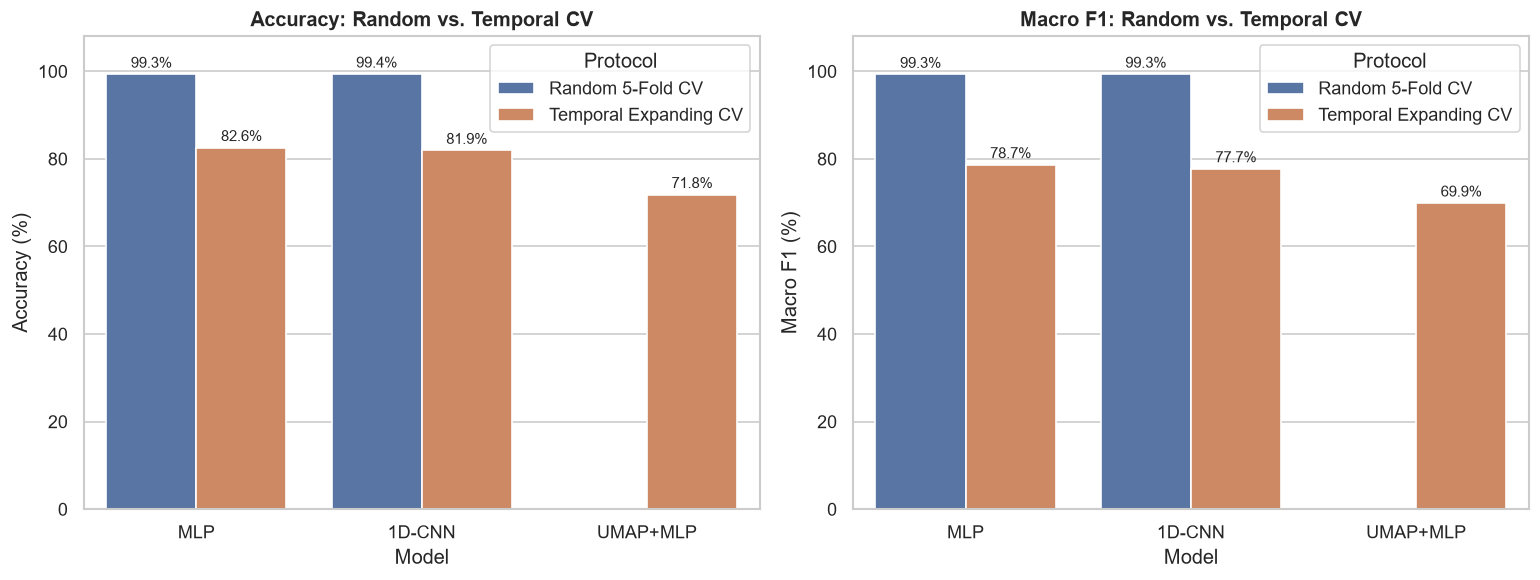

Saved figure: C:\Users\z64x\Desktop\Deeplearn project\figures\05_random_vs_temporal_cv.png


In [6]:
# Compare Random 5-Fold CV vs Temporal Expanding-Window CV
comp_rows = []
for _, row in random_cv_summary.iterrows():
    comp_rows.append({
        "Model": row["model"],
        "Protocol": "Random 5-Fold CV",
        "Accuracy": row["accuracy_mean"] * 100,
        "Macro F1": row["macro_f1_mean"] * 100,
    })
for _, row in temporal_summary.iterrows():
    comp_rows.append({
        "Model": row["model"],
        "Protocol": "Temporal Expanding CV",
        "Accuracy": row["mean_batch_accuracy"] * 100,
        "Macro F1": row["mean_batch_macro_f1"] * 100,
    })
comp_df = pd.DataFrame(comp_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric in zip(axes, ["Accuracy", "Macro F1"]):
    sns.barplot(
        data=comp_df,
        x="Model",
        y=metric,
        hue="Protocol",
        palette=["#4c72b0", "#dd8452"],
        ax=ax,
    )
    ax.set_title(f"{metric}: Random vs. Temporal CV", fontsize=12, fontweight="bold")
    ax.set_ylabel(f"{metric} (%)")
    ax.set_ylim(0, 108)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=2, fontsize=9)

plt.tight_layout()
fig5_path = FIGURES_DIR / "05_random_vs_temporal_cv.png"
fig.savefig(fig5_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig5_path}")

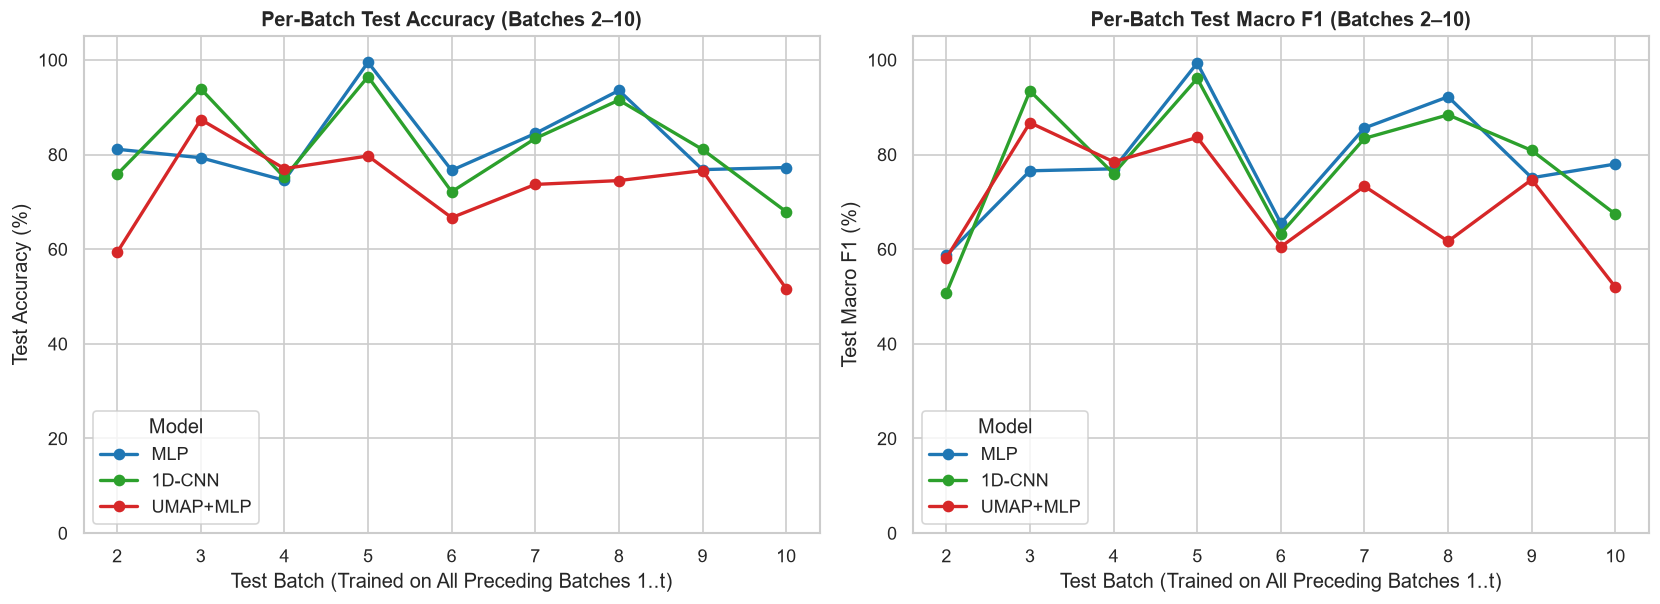

Saved figure: C:\Users\z64x\Desktop\Deeplearn project\figures\06_temporal_accuracy_per_batch.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True)
model_order = ["MLP", "1D-CNN", "UMAP+MLP"]
palette = {"MLP": "#1f77b4", "1D-CNN": "#2ca02c", "UMAP+MLP": "#d62728"}

for ax, col, ylabel, title in [
    (axes[0], "accuracy", "Test Accuracy", "Per-Batch Test Accuracy (Batches 2–10)"),
    (axes[1], "macro_f1", "Test Macro F1", "Per-Batch Test Macro F1 (Batches 2–10)"),
]:
    for m in model_order:
        sub = temporal_per_batch[temporal_per_batch["model"] == m]
        ax.plot(
            sub["test_batch"],
            sub[col] * 100,
            marker="o",
            linewidth=2.0,
            label=m,
            color=palette[m],
        )
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Test Batch (Trained on All Preceding Batches 1..t)")
    ax.set_ylabel(f"{ylabel} (%)")
    ax.set_xticks(range(2, 11))
    ax.set_ylim(0, 105)
    ax.legend(title="Model", frameon=True)

plt.tight_layout()
fig6_path = FIGURES_DIR / "06_temporal_accuracy_per_batch.png"
fig.savefig(fig6_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig6_path}")

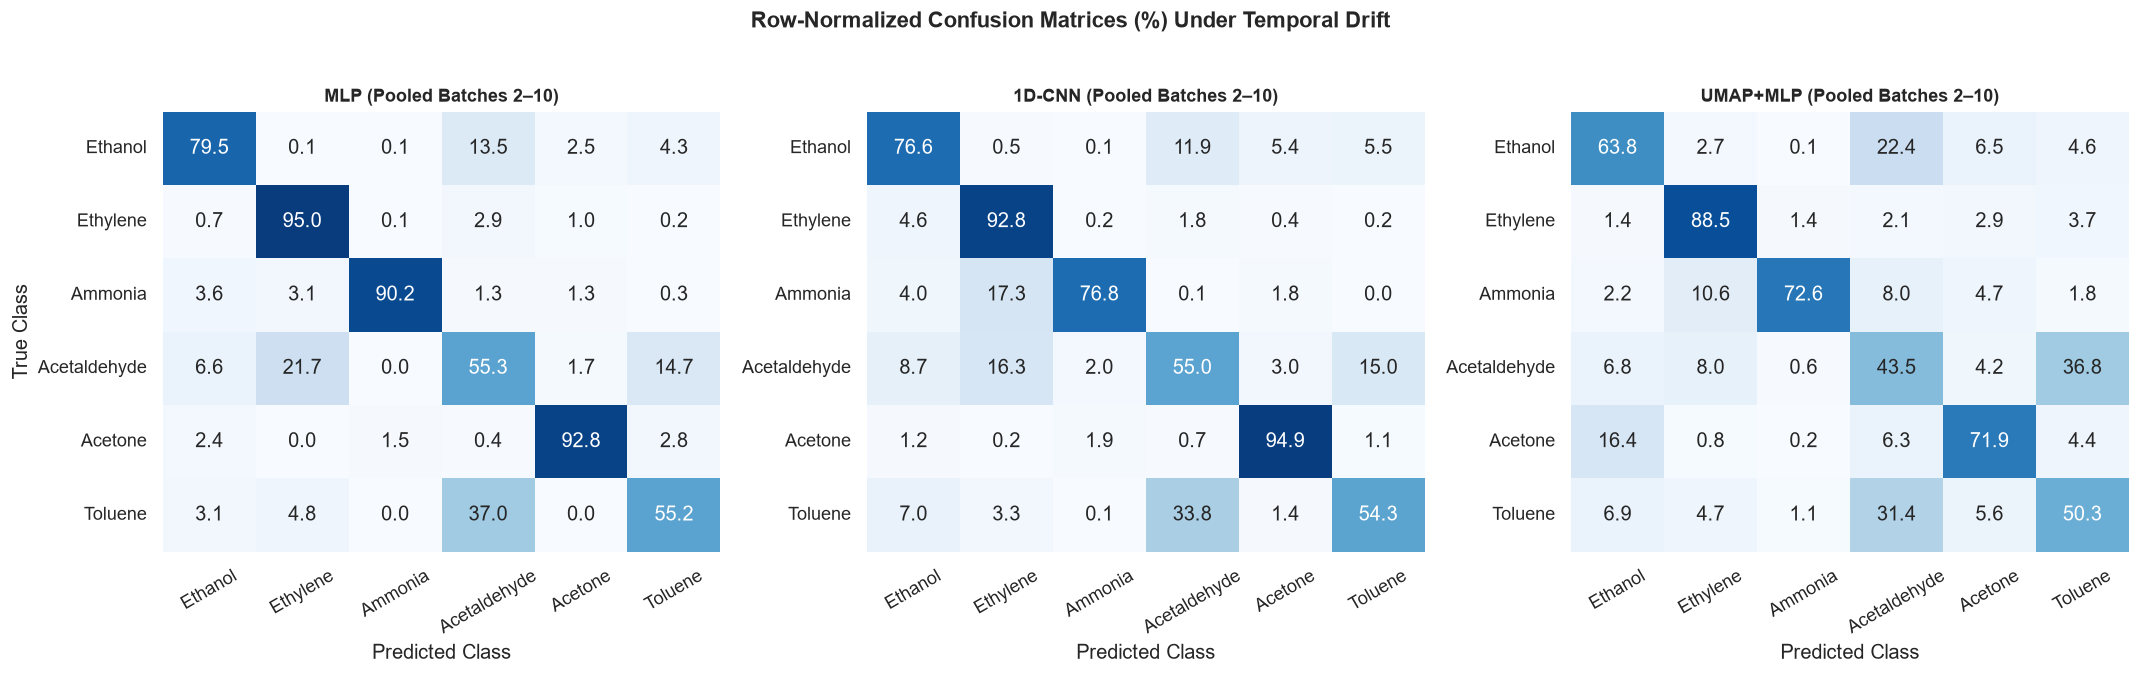

Saved figure: C:\Users\z64x\Desktop\Deeplearn project\figures\07_confusion_matrices_temporal.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, model_name in zip(axes, ["MLP", "1D-CNN", "UMAP+MLP"]):
    y_true_p, y_pred_p = pooled_preds[model_name]
    cm = confusion_matrix(y_true_p, y_pred_p, labels=list(range(6)), normalize="true")
    sns.heatmap(
        cm * 100,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        vmin=0,
        vmax=100,
        xticklabels=gas_names,
        yticklabels=gas_names,
        cbar=False,
        ax=ax,
    )
    ax.set_title(f"{model_name} (Pooled Batches 2–10)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class" if model_name == "MLP" else "")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle("Row-Normalized Confusion Matrices (%) Under Temporal Drift", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig7_path = FIGURES_DIR / "07_confusion_matrices_temporal.png"
fig.savefig(fig7_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig7_path}")